In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

In [2]:
df=pd.read_csv("ObesityDataSet_raw_and_data_sinthetic.csv")

In [3]:

df

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.000000,1.620000,64.000000,yes,no,2.0,3.0,Sometimes,no,2.000000,no,0.000000,1.000000,no,Public_Transportation,Normal_Weight
1,Female,21.000000,1.520000,56.000000,yes,no,3.0,3.0,Sometimes,yes,3.000000,yes,3.000000,0.000000,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.000000,1.800000,77.000000,yes,no,2.0,3.0,Sometimes,no,2.000000,no,2.000000,1.000000,Frequently,Public_Transportation,Normal_Weight
3,Male,27.000000,1.800000,87.000000,no,no,3.0,3.0,Sometimes,no,2.000000,no,2.000000,0.000000,Frequently,Walking,Overweight_Level_I
4,Male,22.000000,1.780000,89.800000,no,no,2.0,1.0,Sometimes,no,2.000000,no,0.000000,0.000000,Sometimes,Public_Transportation,Overweight_Level_II
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2106,Female,20.976842,1.710730,131.408528,yes,yes,3.0,3.0,Sometimes,no,1.728139,no,1.676269,0.906247,Sometimes,Public_Transportation,Obesity_Type_III
2107,Female,21.982942,1.748584,133.742943,yes,yes,3.0,3.0,Sometimes,no,2.005130,no,1.341390,0.599270,Sometimes,Public_Transportation,Obesity_Type_III
2108,Female,22.524036,1.752206,133.689352,yes,yes,3.0,3.0,Sometimes,no,2.054193,no,1.414209,0.646288,Sometimes,Public_Transportation,Obesity_Type_III
2109,Female,24.361936,1.739450,133.346641,yes,yes,3.0,3.0,Sometimes,no,2.852339,no,1.139107,0.586035,Sometimes,Public_Transportation,Obesity_Type_III


In [4]:

df.describe()

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000
mean,24.312600,1.701677,86.586058,2.419043,2.685628,2.008011,1.010298,0.657866
std,6.345968,0.093305,26.191172,0.533927,0.778039,0.612953,0.850592,0.608927
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.947192,1.630000,65.473343,2.000000,2.658738,1.584812,0.124505,0.000000
50%,22.777890,1.700499,83.000000,2.385502,3.000000,2.000000,1.000000,0.625350
75%,26.000000,1.768464,107.430682,3.000000,3.000000,2.477420,1.666678,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF                             21

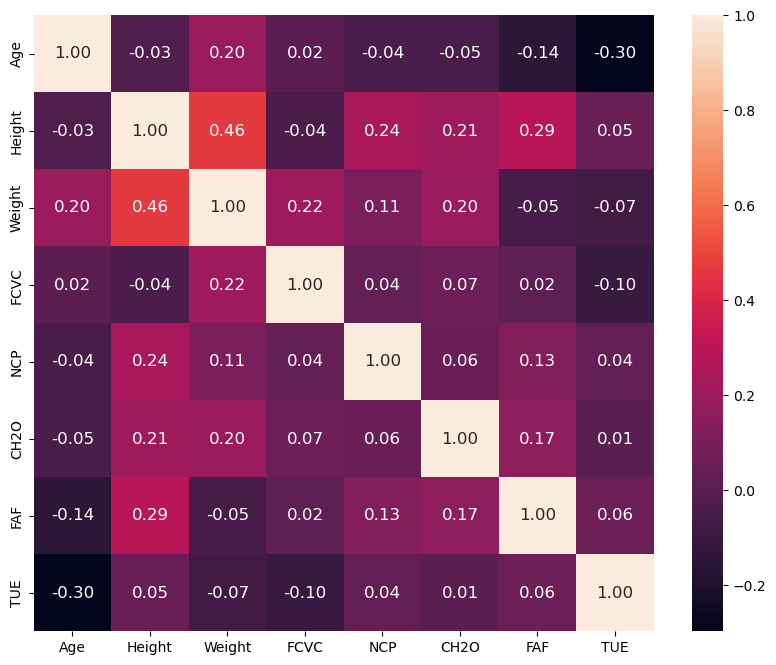

In [6]:
NumericalFeatures=df.select_dtypes(include=['float64',"int64"])
Correlation_matrix=NumericalFeatures.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(Correlation_matrix, annot=True, fmt='.2f',annot_kws={"size": 12},)
plt.show()

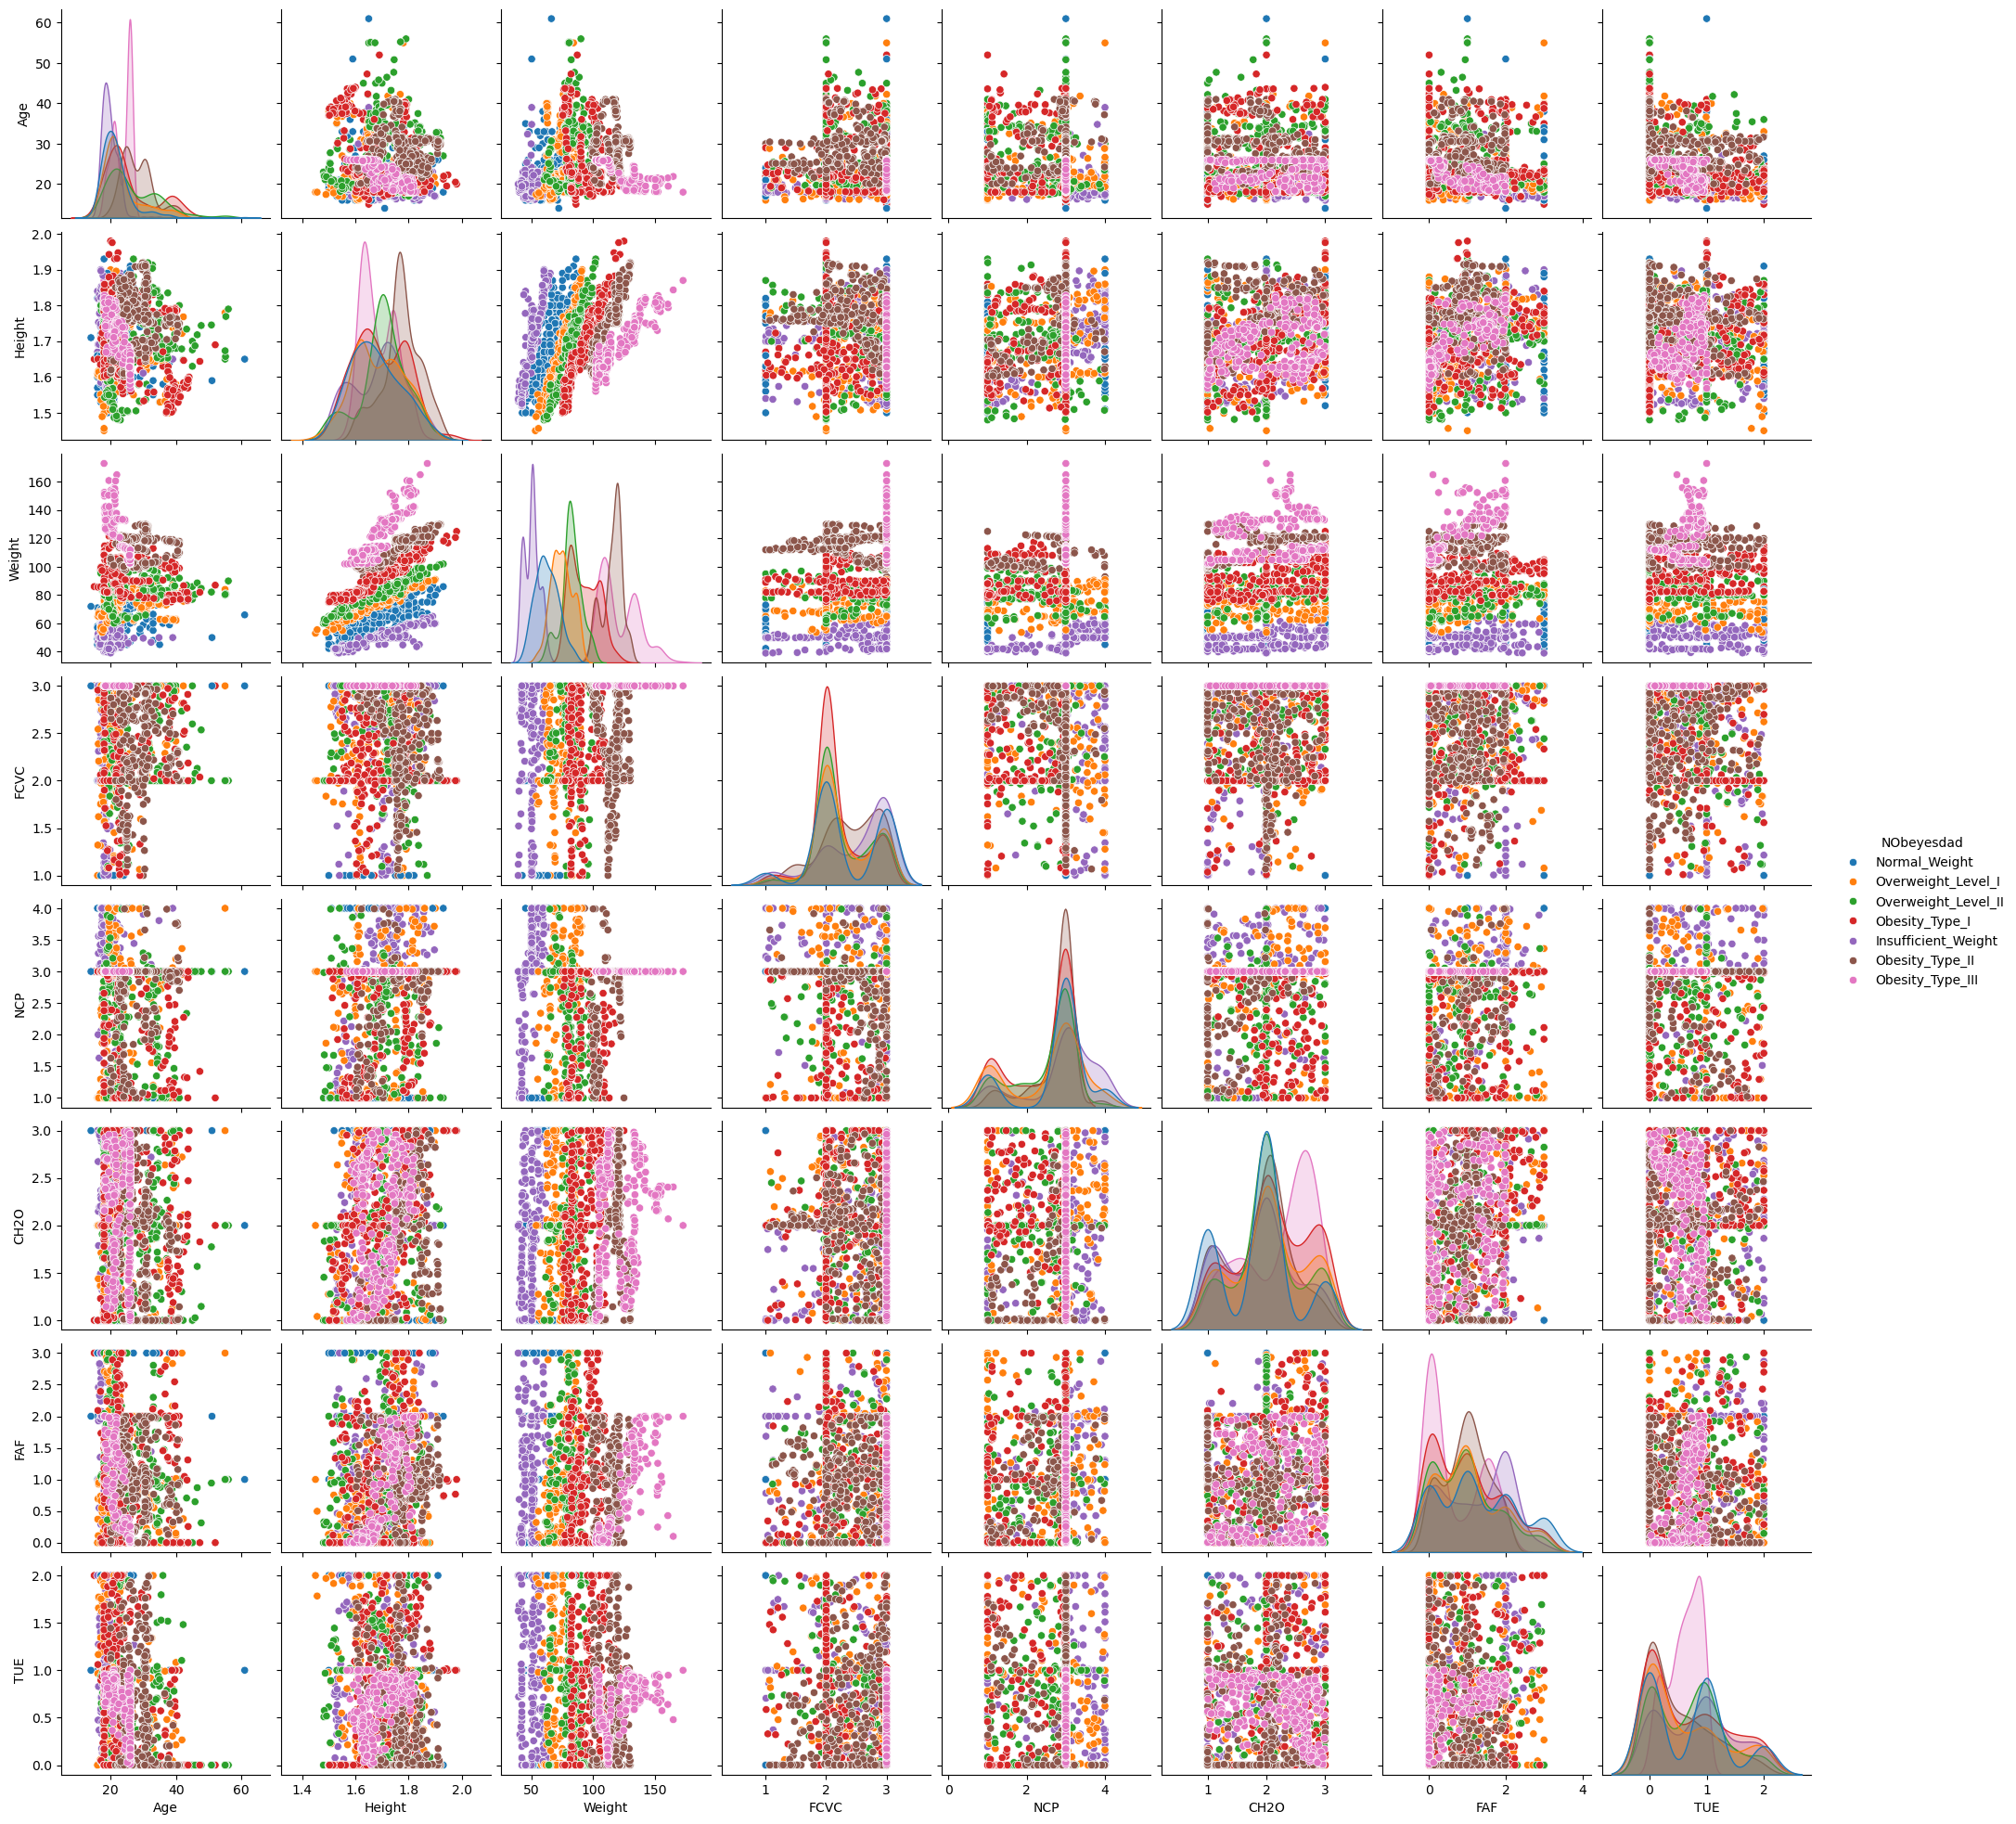

<Figure size 1000x800 with 0 Axes>

In [7]:
sns.pairplot(df, vars=NumericalFeatures , hue="NObeyesdad")
plt.figure(figsize=(10, 8))
plt.show()

In [8]:
Obesity = ['Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III']
condition=[df["NObeyesdad"].isin (Obesity)]
result=["Obesity"]
df["Obesity_NotObesity"]=np.select(condition, result, default="NotObesity")

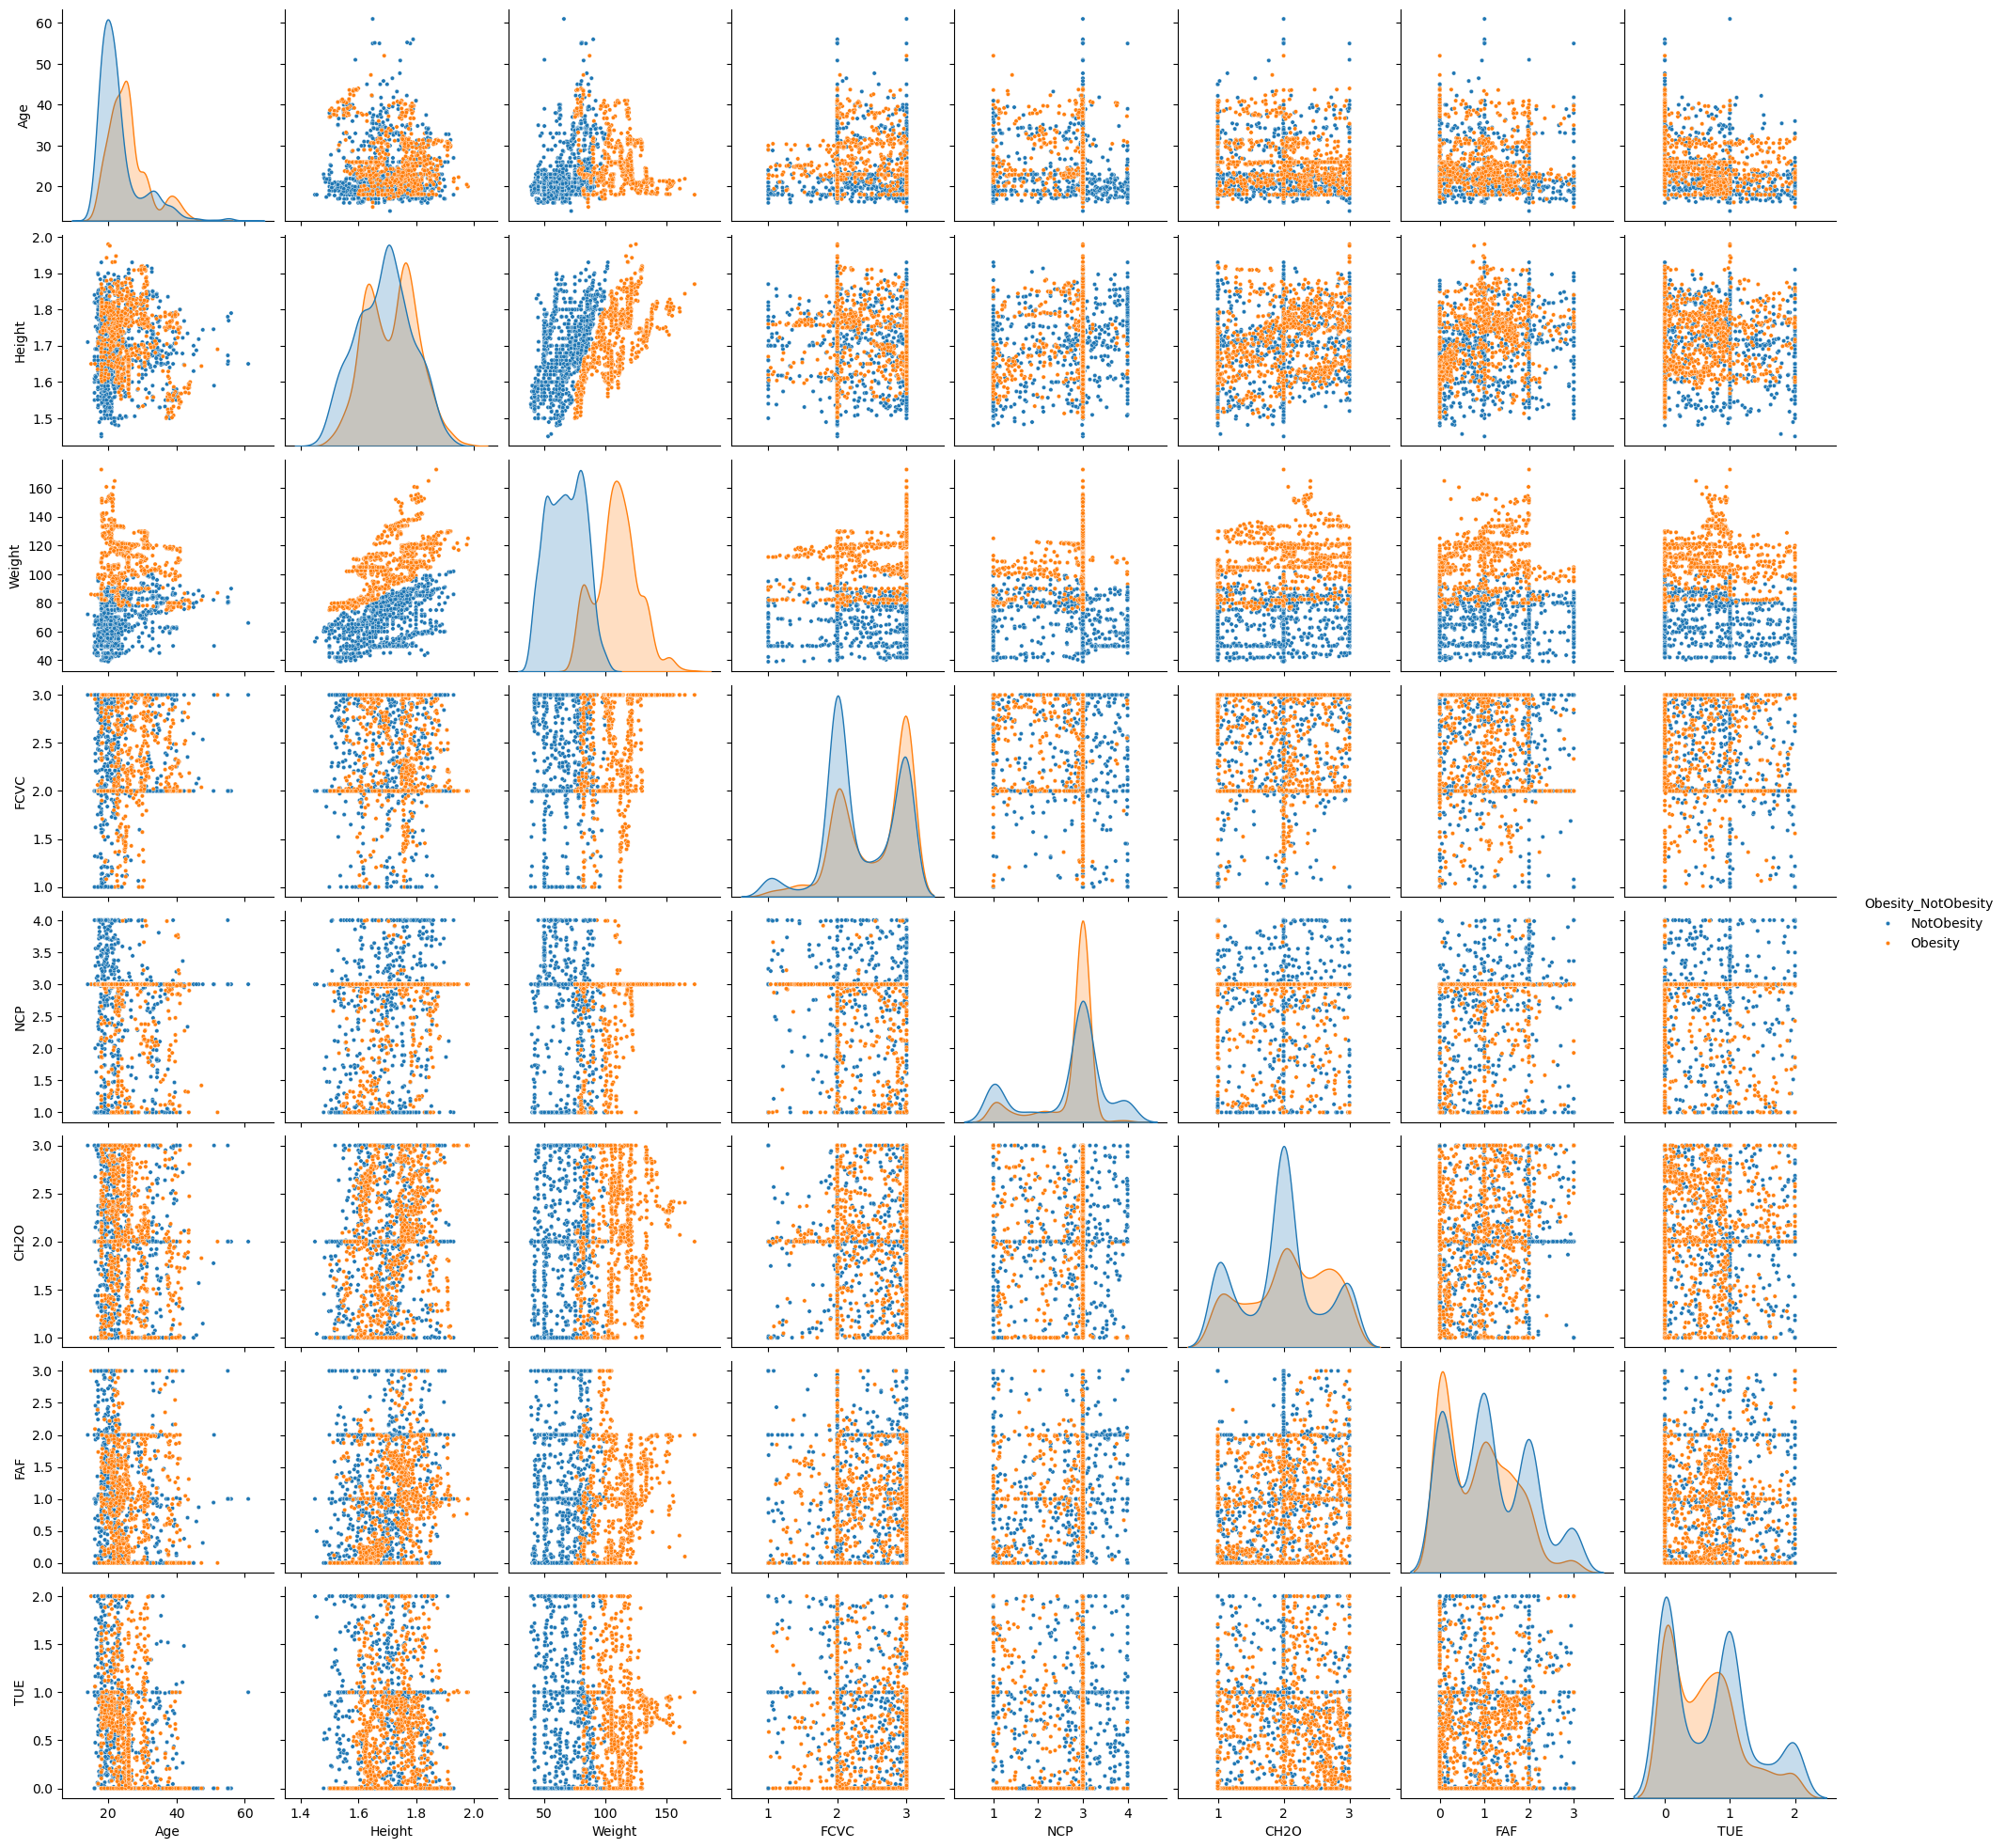

<Figure size 1000x800 with 0 Axes>

In [9]:
sns.pairplot(df, vars=NumericalFeatures , hue="Obesity_NotObesity",plot_kws={'s': 10})
plt.figure(figsize=(10, 8))
plt.show()

In [10]:
NumberTarget={'Insufficient_Weight': 0, 'Normal_Weight': 1,'Overweight_Level_I': 2,'Overweight_Level_II': 3,'Obesity_Type_I': 4,'Obesity_Type_II': 5,'Obesity_Type_III': 6}

In [11]:
df["Number_Target"]=df["NObeyesdad"].map(NumberTarget)

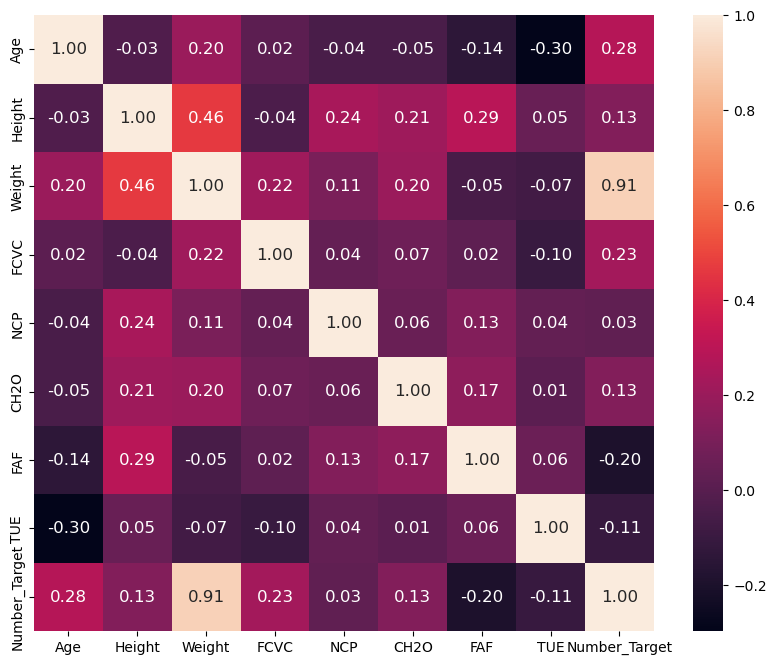

In [12]:
NumericalFeatures=df.select_dtypes(include=['float64',"int64"])
Correlation_matrix=NumericalFeatures.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(Correlation_matrix, annot=True, fmt='.2f',annot_kws={"size": 12},)
plt.show()

In [13]:
NumberGender={'Male': 1, 'Female': 2}
df["Number_Gender"]=df["Gender"].map(NumberGender)

In [14]:
Number_family_history_with_overweightr={'yes': 1, 'no': 2}
df["_Number_family_history_with_overweightr"]=df["family_history_with_overweight"].map(Number_family_history_with_overweightr)

In [15]:
Number_Caloric_Food_Frequently={'yes': 1, 'no': 2}
df["Number_Caloric_Food_Frequently"]=df["FAVC"].map(Number_Caloric_Food_Frequently)

In [16]:
Number_Food_between_meals={'no': 0, 'Sometimes': 1,"Frequently":2, 'Always':3}
df["Number_Food_between_meals"]=df["CAEC"].map(Number_Food_between_meals)

In [17]:
Number_SMOKE={'yes': 1, 'no': 2}
df["Number_SMOKE"]=df["SMOKE"].map(Number_SMOKE)

In [18]:
Number_Monitor_Calories={'yes': 1, 'no': 2}
df["Number_Monitor_Calories"]=df["SCC"].map(Number_Monitor_Calories)

In [19]:
df["CAEC"].unique()

array(['Sometimes', 'Frequently', 'Always', 'no'], dtype=object)

In [20]:
df["CALC"].unique()

array(['no', 'Sometimes', 'Frequently', 'Always'], dtype=object)

In [21]:
Number_Alcohol={'no': 0, 'Sometimes': 1,"Frequently":2, 'Always':3}
df["Number_Alcohol"]=df["CALC"].map(Number_Alcohol)

In [22]:
Number_Alcohol={'no': 0, 'Sometimes': 1,"Frequently":2, 'Always':3}
df["Number_Alcohol"]=df["CALC"].map(Number_Alcohol)

In [23]:
df["MTRANS"].unique()

array(['Public_Transportation', 'Walking', 'Automobile', 'Motorbike',
       'Bike'], dtype=object)

In [24]:
Active_Transport = ['Walking','Bike']
condition=[df["MTRANS"].isin (Active_Transport)]
result=["Active_Transport"]
df["Active_NotActive_Transport"]=np.select(condition, result, default="NotActive_Transport")

In [40]:
df["Active_NotActive_Transport"].unique()

array(['NotActive_Transport', 'Active_Transport'], dtype=object)

In [46]:
Number_Active_NotActive_Transport = {"NotActive_Transport": 1, "Active_Transport": 2}
df["Number_Active_NotActive_Transport"] = df["Active_NotActive_Transport"].map(Number_Active_NotActive_Transport)

In [47]:
df["Number_Active_NotActive_Transport"].unique()

array([1, 2], dtype=int64)

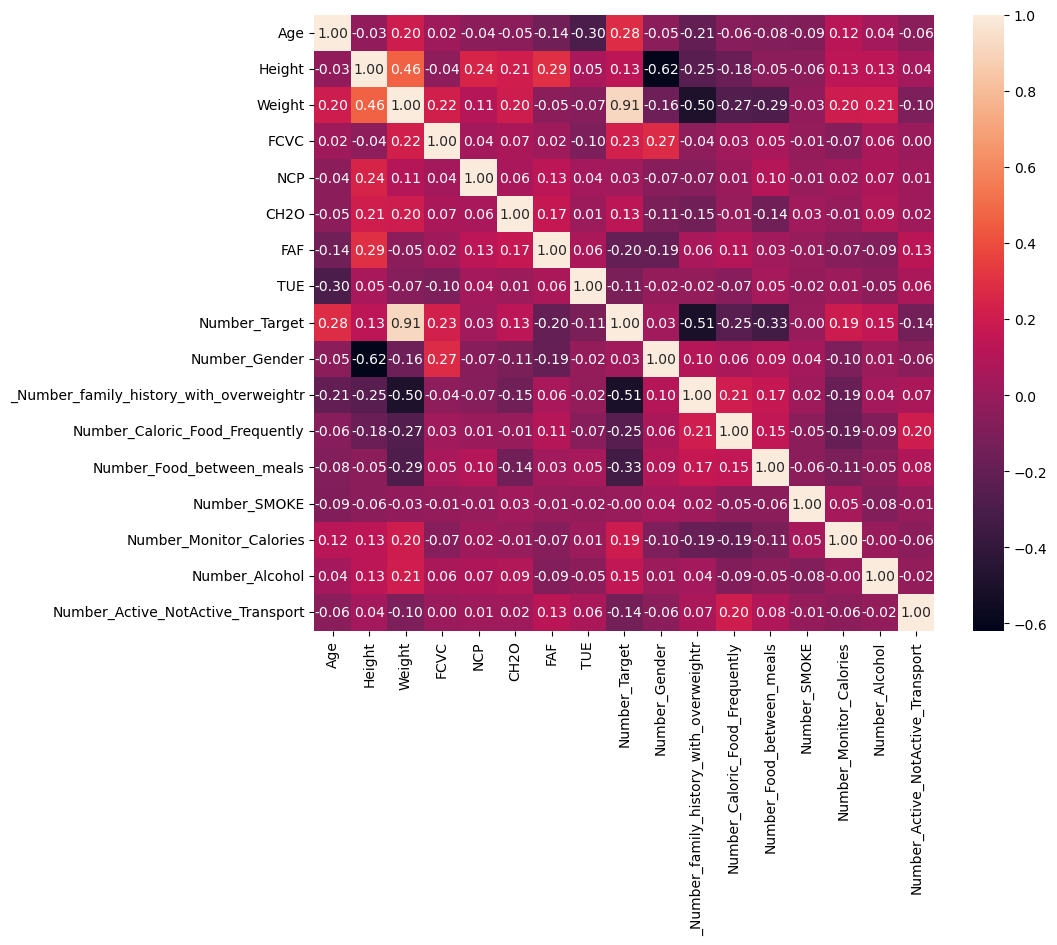

In [48]:
NumericalFeatures=df.select_dtypes(include=['float64',"int64"])
Correlation_matrix=NumericalFeatures.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(Correlation_matrix, annot=True, fmt='.2f',annot_kws={"size": 10},)
plt.show()

In [49]:
df.info ()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 28 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Gender                                   2111 non-null   object 
 1   Age                                      2111 non-null   float64
 2   Height                                   2111 non-null   float64
 3   Weight                                   2111 non-null   float64
 4   family_history_with_overweight           2111 non-null   object 
 5   FAVC                                     2111 non-null   object 
 6   FCVC                                     2111 non-null   float64
 7   NCP                                      2111 non-null   float64
 8   CAEC                                     2111 non-null   object 
 9   SMOKE                                    2111 non-null   object 
 10  CH2O                                     2111 no

In [50]:
Numerical_Features_NOTTarget = df.select_dtypes(include=['float64', 'int64']).drop(columns=[ "Number_Target"], errors='ignore').columns.tolist()

In [51]:
X =df[Numerical_Features_NOTTarget]
y = df["Number_Target"]

In [52]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 1)

In [55]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors = 5, metric = 'euclidean')
knn.fit(X_train, y_train)

KNeighborsClassifier(metric='euclidean')

<Axes: >

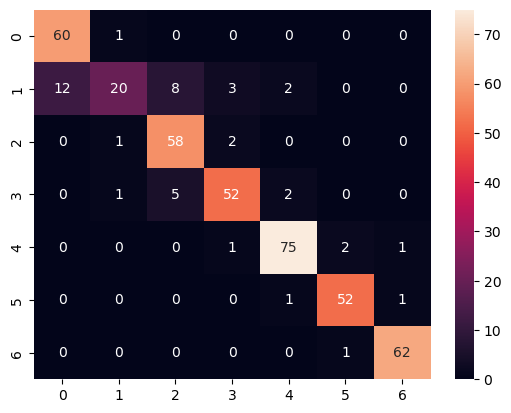

In [57]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Call a method predict by using an object classifier 'cls_svm'
y_predict = knn.predict(X_test)

# Calculate cm by calling a method named as 'confusion_matrix'
cm = confusion_matrix(y_test, y_predict)

# Call a method heatmap() to plot confusion matrix
sns.heatmap(cm, annot = True)

In [58]:
from sklearn.metrics import classification_report

# Display the classification report
print(classification_report(y_test, y_predict))

              precision    recall  f1-score   support

           0       0.83      0.98      0.90        61
           1       0.87      0.44      0.59        45
           2       0.82      0.95      0.88        61
           3       0.90      0.87      0.88        60
           4       0.94      0.95      0.94        79
           5       0.95      0.96      0.95        54
           6       0.97      0.98      0.98        63

    accuracy                           0.90       423
   macro avg       0.90      0.88      0.87       423
weighted avg       0.90      0.90      0.89       423



In [60]:
import numpy as np
neighbors = np.arange(1, 11)                  # number of neighbors
train_accuracy = np.zeros(len(neighbors))     # Declare and initialise the matrix
test_accuracy = np.zeros(len(neighbors))      # Declare and initialise the matrix

In [61]:
for i, k in enumerate(neighbors):                          # for loop that checks the model for neighbor values 1, 2, 3, ..., 10
    kNN = KNeighborsClassifier(n_neighbors = k)            # Initialise an object knn using KNeighborsClassifier method

    # Fit the model
    kNN.fit(X_train, y_train)                              # Call fit method to implement the ML KNeighborsClassifier model

    # Compute accuracy on the training set
    train_accuracy[i] = kNN.score(X_train, y_train)        # Save the score value in the train_accuracy array

    # Compute accuracy on the test set
    test_accuracy[i] = kNN.score(X_test, y_test)           # Save the score value in the train_accuracy array

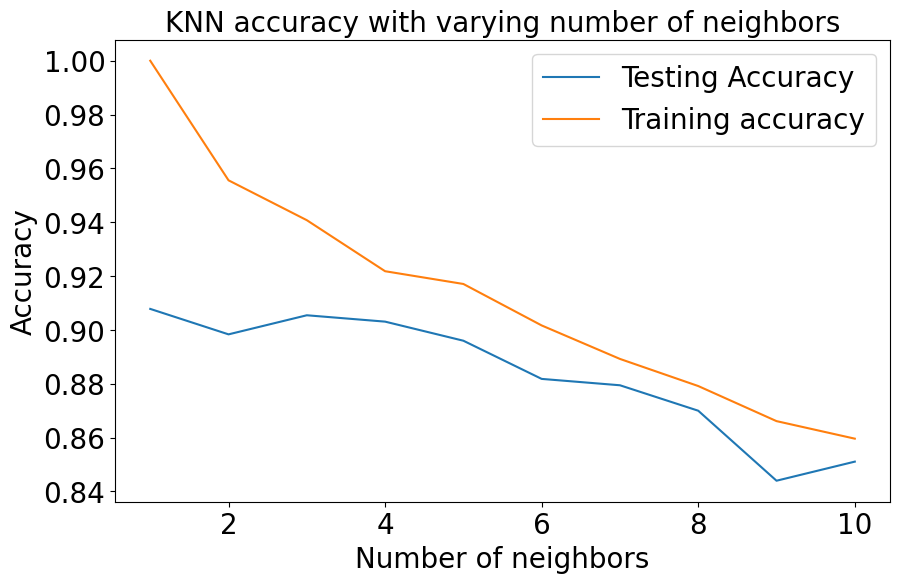

In [62]:
import matplotlib.pyplot as plt

plt.figure(figsize = (10, 6))
plt.title('KNN accuracy with varying number of neighbors', fontsize = 20)
plt.plot(neighbors, test_accuracy, label = 'Testing Accuracy')
plt.plot(neighbors, train_accuracy, label = 'Training accuracy')
plt.legend(prop={'size': 20})
plt.xlabel('Number of neighbors', fontsize = 20)
plt.ylabel('Accuracy', fontsize = 20)
plt.xticks(fontsize = 20)
plt.yticks(fontsize = 20)
plt.show()